In [1]:
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import numpy.random as nr
import jax
import scipy
from gestimators import BF
from IMH2 import IndMH
import matplotlib.pyplot as plt
from gdistribution import gprior, mix_normal

2023-11-28 17:22:38.724222: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


In [2]:
# def load_data():
#         file = '/home/ranbot/optionpricing/data/ripley.mat'
#         mat = scipy.io.loadmat(file)
#         data = mat['X']
#         inputs = data[:, 0:-1]
#         print(inputs.shape)
#         outputs = data[:, -1]
#         return inputs, outputs

# input, output = load_data()

In [3]:
n_predata = 50
def gen_data():
    X = nr.multivariate_normal(np.zeros(5), np.eye(5), n_predata)
    y = np.zeros(n_predata)
    for i in range(n_predata):
        y[i] = nr.normal(X[i,3] + 2*X[i,4], 2.5)
    return X, y

input, output = gen_data()
input = input[:, 3:]
dim = 2

cov0 = np.linalg.inv(input.T @ input)
print(cov0)

[[0.01477005 0.00061282]
 [0.00061282 0.02111647]]


0 [0.33333333 0.33333333 0.33333333] [3.04025396 3.54132694 9.87398811] 1.0
1 [0.39389191 0.36018222 0.24592587] [ 2.68119566  3.08507381 16.91297189] 0.9999999999999998
2 [0.45541744 0.38663156 0.157951  ] [ 2.19842134  2.62594817 27.30761617] 0.9999999999999997
3 [0.49583361 0.39059411 0.11357227] [ 2.09488816  2.71704769 37.28451113] 0.9999999999999996
4 [0.52829855 0.37774236 0.0939591 ] [ 1.68627129  2.53897864 47.78157029] 0.9999999999999998
5 [0.55523558 0.35354189 0.09122253] [ 1.0624238   2.18111772 54.62894987] 1.0
6 [0.56952986 0.32920489 0.10126525] [ 0.72079637  2.45455022 50.64689898] 0.9999999999999993
7 [0.58668287 0.31140214 0.10191499] [ 0.53812564  2.98300978 50.04843715] 0.9999999999999996
8 [0.59780149 0.30798409 0.09421441] [ 0.45785999  3.49603175 53.01474037] 1.0
9 [0.60070553 0.31499292 0.08430156] [ 0.4177326   3.85640405 57.90177369] 1.0000000000000007
10 [0.59838587 0.32602104 0.07559309] [ 0.39501189  4.07988753 63.27283331] 1.0000000000000004
11 [0.5940620

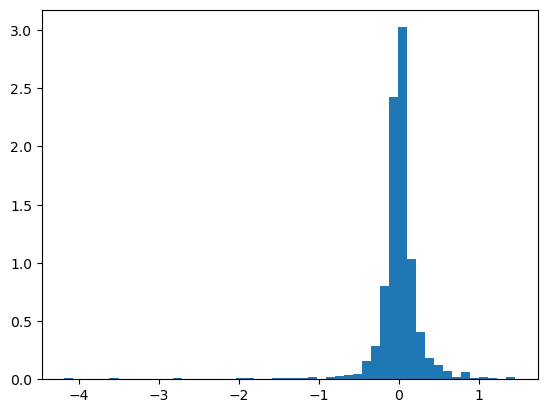

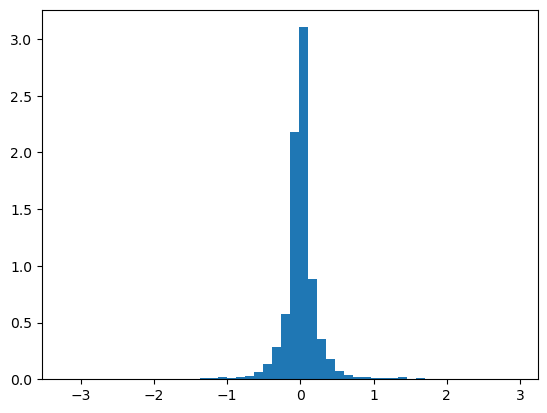

In [4]:
nc = 3
tar = gprior(dim)
tar.set_parameters(cov0)
pro = mix_normal(dim)
a = tar.sampler(1000)

pro.em_algorithm(a,nc,cov0,50)
weights = pro.weights
covs = pro.covs
print(weights, covs)

# covs = np.array([np.cov(a[:,0], a[:,1])])
b = pro.sampler(10000)
plt.hist(a[:,0], bins = 50, density = True)
plt.show()
plt.hist(b[:,0], bins = 50, density = True)
plt.show()

In [5]:
Itrnum = 1100
sample_size = 1000
target = 'gprior'
proposal = 'mix_normal'

MyIM = IndMH(Itrnum, dim, target, proposal)
MyIM.set_distribution_parameters(cov0, nc, weights, covs)
est = BF(sample_size, weights, covs, input, output)
estcmc = BF(sample_size, weights, covs, input, output)
tar = gprior(dim)
tar.set_parameters(cov0)

In [11]:
epoch = 20
cmc_mean = []
imhcv_mean = []
print("start")
for i in range(epoch):
    data = MyIM.IMH()
    print(data[2].mean())
    est.sample_loader(data[0],data[1],data[2])
    m,v= est.IMCV()
    imhcv_mean.append(m)
    # datacmc = tar.sampler(sample_size)
    # estcmc.cmc_loader(datacmc)
    # mc,vc = estcmc.CMC()
    mc,vc = est.IM()
    cmc_mean.append(mc)
    if (i + 1) % 1 == 0:
        print(i + 1, "replications completed !")

start
0.8425043979558078
[[ 3.31928536e-249 -3.32006312e-249]
 [-3.32006312e-249  3.50271880e-249]]
[[3.50271880e-249 7.80306988e-250]
 [7.80306988e-250 3.31928555e-249]]
[[ 1.         -0.97369157]
 [-0.97369157  1.        ]]
[[1.         0.22884454]
 [0.22884454 1.        ]]
3.547330285638755e-20 0.23531813202288626
1 replications completed !
0.83938424941491
[[ 2.04857048e-249 -2.04901976e-249]
 [-2.04901976e-249  2.14675103e-249]]
[[2.14675103e-249 4.48488392e-250]
 [4.48488392e-250 2.04863159e-249]]
[[ 1.         -0.97707939]
 [-0.97707939  1.        ]]
[[1.         0.21385944]
 [0.21385944 1.        ]]
2.52449860607023e-20 0.2191400985813461
2 replications completed !
0.8488614420050924
[[0.00000000e+000 0.00000000e+000]
 [0.00000000e+000 3.68602033e-313]]
[[ 3.68602033e-313 -3.51258379e-302]
 [-3.51258379e-302  1.30208172e-259]]
[[nan nan]
 [nan  1.]]
[[ 1.00000000e+00 -1.60335138e-16]
 [-1.60335138e-16  1.00000000e+00]]
0.0 -2.7003680677087006e-43
3 replications completed !


/home/cliusir/anaconda3/envs/statr/lib/python3.10/site-packages/numpy/lib/function_base.py:2829: RuntimeWarning: invalid value encountered in true_divide
  c /= stddev[:, None]
/home/cliusir/anaconda3/envs/statr/lib/python3.10/site-packages/numpy/lib/function_base.py:2830: RuntimeWarning: invalid value encountered in true_divide
  c /= stddev[None, :]


0.8389520346441052
[[ 9.82548350e-320 -4.70796755e-310]
 [-4.70796755e-310  2.25141538e-294]]
[[ 2.25141538e-294 -1.41234687e-292]
 [-1.41234687e-292  1.30208172e-259]]
[[ 1.         -0.00100099]
 [-0.00100099  1.        ]]
[[ 1.0000000e+00 -2.6085216e-16]
 [-2.6085216e-16  1.0000000e+00]]
-1.1450228285595487e-16 -1.0857695141930843e-33
4 replications completed !
0.8259983466091481
[[0.00000000e+000 0.00000000e+000]
 [0.00000000e+000 3.71127631e-302]]
[[3.71127631e-302 6.56316864e-297]
 [6.56316864e-297 1.30208172e-259]]
[[nan nan]
 [nan  1.]]
[[1.00000000e+00 9.44132176e-17]
 [9.44132176e-17 1.00000000e+00]]
0.0 5.045565341667637e-38
5 replications completed !
0.8414172306927767
[[0. 0.]
 [0. 0.]]
[[0.00000000e+000 5.34552278e-309]
 [5.34552278e-309 1.30208172e-259]]
[[nan nan]
 [nan nan]]
[[nan  1.]
 [ 1.  1.]]
nan 4.1094760707723834e-50
6 replications completed !


/home/cliusir/STAT/optionpricing/OPTIONPRICING/gexp/gestimators.py:49: RuntimeWarning: invalid value encountered in double_scalars
  coef = numerator / denominator
/home/cliusir/anaconda3/envs/statr/lib/python3.10/site-packages/numpy/lib/function_base.py:2829: RuntimeWarning: divide by zero encountered in true_divide
  c /= stddev[:, None]
/home/cliusir/anaconda3/envs/statr/lib/python3.10/site-packages/numpy/lib/function_base.py:2830: RuntimeWarning: divide by zero encountered in true_divide
  c /= stddev[None, :]


0.8302067188173532
[[ 2.08105247e-240 -2.00347860e-240]
 [-2.00347860e-240  4.00984678e-240]]
[[4.00984678e-240 2.08305587e-240]
 [2.08305587e-240 2.08105247e-240]]
[[ 1.         -0.69355244]
 [-0.69355244  1.        ]]
[[1.         0.72110003]
 [0.72110003 1.        ]]
1.2736782371860343e-12 1.0019646500669177
7 replications completed !
0.8454154852980917
[[ 9.17704920e-300 -1.43850153e-298]
 [-1.43850153e-298  1.97231899e-291]]
[[1.97231899e-291 5.90617783e-292]
 [5.90617783e-292 1.30208172e-259]]
[[ 1.         -0.00106923]
 [-0.00106923  1.        ]]
[[1.00000000e+00 3.68552041e-17]
 [3.68552041e-17 1.00000000e+00]]
-6.195121764833744e-08 4.540490695716535e-33
8 replications completed !
0.8420171791315079
[[ 1.74572267e-299 -5.34222193e-287]
 [-5.34222193e-287  1.63154692e-268]]
[[ 1.63154692e-268 -5.08219137e-280]
 [-5.08219137e-280  1.30208172e-259]]
[[ 1.       -0.001001]
 [-0.001001  1.      ]]
[[ 1.00000000e+00 -1.10263585e-16]
 [-1.10263585e-16  1.00000000e+00]]
-2.88760185422

In [12]:
print(np.array(imhcv_mean).var())
print(np.array(cmc_mean).var())
print(np.array(imhcv_mean).mean())
print(np.array(cmc_mean).mean())
print(np.array(cmc_mean).var()/np.array(imhcv_mean).var())

nan
1.0636383117450257e-200
nan
2.391124079196883e-101
nan
